In [1]:
'''
gonna change the threshold on detection certainty
and see what we can learn from the precision and recall
of the efficiency data
'''

'\ngonna change the threshold on detection certainty\nand see what we can learn from the precision and recall\nof the efficiency data\n'

In [3]:
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt
import precision_recall as pr
import gc  # garbage collector
import review_findings_functions as rff
import os
import importlib

In [4]:
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [8]:
float(.5)

0.5

In [9]:
!python pimg_to_dataframe_varthresh.py "newrange_25_mindelta_p50" .5

ztf_20221020294271_000449_zr_c16_x_0020._2_predsarray.npy
ztf_20221020148032_000686_zg_c03_x_0011._2_predsarray.npy
^C
Traceback (most recent call last):
  File "/home/3155/rwe/pimg_to_dataframe_varthresh.py", line 63, in <module>
    alllist = rff.make_obj_list(predsarray, abst_thr, filename_start, quad)
              ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/3155/rwe/review_findings_functions.py", line 3055, in make_obj_list
    objsizes_both = pr.get_objsizes(labs, nlabs)
                    ^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/3155/rwe/precision_recall.py", line 225, in get_objsizes
    howmany = ((i + 1) == labs).sum()
              ^^^^^^^^^^^^^^^^^^^^^^^
  File "/lustre/lrspec/users/3155/anaconda3/envs/trans/lib/python3.11/site-packages/numpy/core/_methods.py", line 47, in _sum
    def _sum(a, axis=None, dtype=None, out=None, keepdims=False,
    
KeyboardInterrupt


In [19]:
!ls /lustre/lrspec/ZTF_data/efficiency_testing/new_eff_data/full_image_implantations_pos/predsarrays_newrange_25_mindelta_p50 

df_concat
df_matched
ztf_20221020138241_000686_zi_c02_x_0029._1_alllist
ztf_20221020138241_000686_zi_c02_x_0029._1_predsarray.npy
ztf_20221020138241_000686_zi_c02_x_0029._3_alllist
ztf_20221020138241_000686_zi_c02_x_0029._3_predsarray.npy
ztf_20221020138241_000686_zi_c02_x_0029._4_alllist
ztf_20221020138241_000686_zi_c02_x_0029._4_predsarray.npy
ztf_20221020148032_000686_zg_c03_x_0011._1_alllist
ztf_20221020148032_000686_zg_c03_x_0011._1_predsarray.npy
ztf_20221020148032_000686_zg_c03_x_0011._2_alllist
ztf_20221020148032_000686_zg_c03_x_0011._2_predsarray.npy
ztf_20221020148032_000686_zg_c03_x_0011._3_alllist
ztf_20221020148032_000686_zg_c03_x_0011._3_predsarray.npy
ztf_20221020148032_000686_zg_c07_x_0013._1_alllist
ztf_20221020148032_000686_zg_c07_x_0013._1_predsarray.npy
ztf_20221020148032_000686_zg_c07_x_0013._3_alllist
ztf_20221020148032_000686_zg_c07_x_0013._3_predsarray.npy
ztf_20221020148032_000686_zg_c07_x_0013._4_alllist
ztf_20221020148032_000686_zg_c07_x_0013._4_predsarray.np

In [21]:
!python concat.py "/lustre/lrspec/ZTF_data/efficiency_testing/new_eff_data/full_image_implantations_pos/predsarrays_newrange_25_mindelta_p50/" "df_concat" "alllist"

Number of transient candidates reduced from 445 to 440.
Number of transient candidates reduced from 133 to 130.
Number of transient candidates reduced from 491 to 487.
Number of transient candidates reduced from 150 to 149.
Number of transient candidates reduced from 148 to 146.
Number of transient candidates reduced from 329 to 328.
Number of transient candidates reduced from 37 to 37.
Number of transient candidates reduced from 174 to 174.
Number of transient candidates reduced from 410 to 408.
Number of transient candidates reduced from 395 to 392.
Number of transient candidates reduced from 674 to 670.
Number of transient candidates reduced from 564 to 559.
Number of transient candidates reduced from 146 to 146.
Number of transient candidates reduced from 96 to 96.
Number of transient candidates reduced from 259 to 258.
Number of transient candidates reduced from 305 to 303.
Number of transient candidates reduced from 382 to 378.
Number of transient candidates reduced from 188 to 1

In [20]:
!python concat.py "/lustre/lrspec/ZTF_data/efficiency_testing/new_eff_data/full_image_implantations_pos/predsarrays_newrange_25_mindelta_p50/" "df_concat_thr_0.5" "alllist_thr_0.5"

Number of transient candidates reduced from 981 to 968.


In [23]:
!python add_to_eff_dfs_varthresh.py "newrange_25_mindelta_p50" 0.5

Traceback (most recent call last):
  File "/home/3155/rwe/add_to_eff_dfs_varthresh.py", line 44, in <module>
    df = pd.read_csv(f"{df_neg_base_path+df_paths[i]}"+"df_concat_thr_"+str(thresh))
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/lustre/lrspec/users/3155/anaconda3/envs/trans/lib/python3.11/site-packages/pandas/util/_decorators.py", line 211, in wrapper
    return func(*args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^
  File "/lustre/lrspec/users/3155/anaconda3/envs/trans/lib/python3.11/site-packages/pandas/util/_decorators.py", line 331, in wrapper
    return func(*args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^
  File "/lustre/lrspec/users/3155/anaconda3/envs/trans/lib/python3.11/site-packages/pandas/io/parsers/readers.py", line 950, in read_csv
    return _read(filepath_or_buffer, kwds)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/lustre/lrspec/users/3155/anaconda3/envs/trans/lib/python3.11/site-packages/pandas/io/pars

In [32]:
df = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/new_eff_data/full_image_implantations_pos/predsarrays_newrange_25_mindelta_p50/df_matched_thr_0.5")

In [33]:
df

,Unnamed: 0.1,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,closest_y,...,brightness_ranking,quadrant,num_in_file_in_star,dup_indices,is_smaller_dup,dist_to_implant,row_from_implant,col_from_implant,A_from_implant,sig_from_implant
0,0,0,ztf_20221020148032_000686_zg_c16_x_0014.,3,pos,18.259259,157.851852,27,169.0,256.0,...,20,3,414.0,[],0.0,130.174016,105.0,273.0,1.005,7.0
1,1,1,ztf_20221020148032_000686_zg_c16_x_0014.,3,pos,16.692308,565.384615,13,576.0,1873.0,...,22,3,317.0,[36],0.0,123.026937,116.0,660.0,10.000,3.0
2,2,2,ztf_20221020148032_000686_zg_c16_x_0014.,3,pos,16.500000,1103.000000,8,1073.0,1903.0,...,13,3,951.0,[37],0.0,76.080549,78.0,1057.0,1.500,4.0
3,3,3,ztf_20221020148032_000686_zg_c16_x_0014.,3,pos,16.928571,2325.428571,14,2337.0,1699.0,...,0,3,296.0,[ 9 33],0.0,54.815693,76.0,2311.0,10.000,4.0
4,4,4,ztf_20221020148032_000686_zg_c16_x_0014.,3,pos,17.285714,274.857143,14,285.0,880.0,...,6,3,661.0,[10 41],1.0,78.613625,105.0,273.0,1.005,7.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
166013,166013,166013,ztf_20221020154120_000640_zi_c15_x_0028.,1,neg,3053.666667,1916.333333,9,1926.0,694.0,...,22,1,257.0,[165989],1.0,655.930298,2412.0,2001.0,2.000,4.0
166014,166014,166014,ztf_20221020154120_000640_zi_c15_x_0028.,1,neg,3054.692308,1029.307692,13,984.0,1417.0,...,15,1,533.0,[165992],0.0,640.084097,2433.0,936.0,5.000,6.0
166015,166015,166015,ztf_20221020154120_000640_zi_c15_x_0028.,1,neg,3054.400000,2287.200000,5,2298.0,767.0,...,14,1,754.0,[165994],1.0,707.441870,2373.0,2447.0,2.000,8.0
166016,166016,166016,ztf_20221020154120_000640_zi_c15_x_0028.,1,neg,3054.000000,533.000000,1,603.0,2501.0,...,9,1,344.0,[],0.0,679.473325,2444.0,821.0,1.010,6.0


In [9]:
def get_efficiency(df, df_implant, distance_threshold, posneg):
    df_cut = df[df['dist_to_implant']<=distance_threshold]
    df_cut = df_cut[df_cut['type']==posneg]
    df_cut.drop_duplicates(subset=["filename", "type","row_from_implant", "col_from_implant"], inplace=True)
    return len(df_cut),len(df_implant)

In [11]:
df_implants_pos = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/new_eff_data/full_image_implantations_pos/df_implants_pos")
df_implants_neg = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/new_eff_data/full_image_implantations_neg/df_implants_neg")


In [34]:
threshold = 20

print(f"\npos-implantation image efficiency of detecting implantations within {threshold}")
# for key in dfs_pos.keys():
# print(key, np.sum(dfs_pos[key])['is_smaller_dup']==0)
cut_len, implant_len = get_efficiency(df, df_implants_pos, threshold, 'pos')
print(f"{(100*cut_len/implant_len):.1f} %, with precision {100*pr.precision(num_true_retrieved=cut_len, num_all_retrieved=len(df)):.1f} %")
    
# print(f"\nneg-implantation image efficiency of detecting implantations within {threshold}")
# for key in dfs_neg.keys():
#     # print(key, np.sum(dfs_pos[key])['is_smaller_dup']==0)
#     cut_len, implant_len = get_efficiency(dfs_neg[key], df_implants_neg, threshold, 'neg')
#     print(key, f"{(100*cut_len/implant_len):.1f} %, with precision {100*pr.precision(num_true_retrieved=cut_len, num_all_retrieved=len(dfs_neg[key])):.1f} %")



pos-implantation image efficiency of detecting implantations within 20
97.8 %, with precision 0.6 %


In [47]:
np.concatenate((np.array([np.array([0,0,0]),np.array([0,0,0])]),np.array([np.array([0,0,0])])))

array([[0, 0, 0],
       [0, 0, 0],
       [0, 0, 0]])

In [ ]:
#okay so something like 
[.2,.3,.4,.5,.6,.7,.8,.9,.95]

In [48]:
import precision_recall as pr

In [49]:
pr.recall?

Signature: pr.recall(num_true_retrieved, num_all_true)
Docstring:
recall: relevant retrieved instances over all relevant instances
both inputs are ints or floats
returns float
File:      ~/rwe/precision_recall.py
Type:      function

In [7]:
def plot_precision_recall_from_eff_data(test_name):
    threshes = ["0.8","0.9","0.95", "0.9999"] #["0.2","0.3","0.4","0.5","0.6","0.7",
    threshold=20
    precisions_pos = np.zeros(len(threshes))
    recalls_pos = np.zeros(len(threshes))
    precisions_neg = np.zeros(len(threshes))
    recalls_neg = np.zeros(len(threshes))
    for i, thr in enumerate(threshes):
        for posneg in ["pos","neg"]:
            df = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/new_eff_data/full_image_implantations_"+posneg+"/predsarrays_"+test_name+"/df_matched_thr_"+thr)
            if posneg=="pos":
                cut_len, implant_len = get_efficiency(df, df_implants_pos, threshold, posneg)
                # print(posneg, thr, len(df), cut_len, cut_len/len(df_implants_pos))
                precision = pr.precision(num_true_retrieved=cut_len, num_all_retrieved=len(df))
                # print(precision)
                recall = pr.recall(num_true_retrieved=cut_len, num_all_true=len(df_implants_pos))
                # print(recall)
                precisions_pos[i]=precision
                recalls_pos[i]=recall
            else:
                cut_len, implant_len = get_efficiency(df, df_implants_neg, threshold, posneg)
                precision = pr.precision(num_true_retrieved=cut_len, num_all_retrieved=len(df))
                recall = pr.recall(num_true_retrieved=cut_len, num_all_true=len(df_implants_neg))
                precisions_neg[i]=precision
                recalls_neg[i]=recall
    plt.plot(threshes, precisions_pos, label="Precision, Brightening", linewidth=3, c="#cc79a7")
    plt.plot(
        threshes,
        precisions_neg,
        label="Precision, Dimming",
        linewidth=3,
        linestyle="dashed",
        c="#cc79a7",
    )
    plt.plot(threshes, recalls_pos, label="Recall, Brightening", linewidth=3, c="#009e73")
    plt.plot(
        threshes,
        recalls_neg,
        label="Recall, Dimming",
        linewidth=3,
        linestyle="dashed",
        c="#009e73",
    )

    plt.legend(fontsize=18)
    plt.title(
        "Precision and Recall Curves from Eff Data for Brightening and Dimming Transients: "+test_name, fontsize=18
    )
    plt.xlabel("Threshold", fontsize=18)
    plt.ylabel("Precision and Recall", fontsize=18)
    # plt.ylim(0.15, 1.01)
    plt.tick_params(axis="both", labelsize=18)
    plt.show()
    return precisions_pos, recalls_pos, precisions_neg, recalls_neg

In [39]:
def plot_precision_recall_from_eff_data(test_name):
    threshes = ["0.5","0.6","0.7","0.8","0.9","0.95", "0.9999"]
    threshold=20
    precisions_pos = np.zeros(len(threshes))
    recalls_pos = np.zeros(len(threshes))
    precisions_neg = np.zeros(len(threshes))
    recalls_neg = np.zeros(len(threshes))
    for i, thr in enumerate(threshes):
        for posneg in ["pos","neg"]:
            df = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/new_eff_data/full_image_implantations_"+posneg+"/predsarrays_"+test_name+"/df_matched_thr_"+thr)
            if posneg=="pos":
                cut_len, implant_len = get_efficiency(df, df_implants_pos, threshold, posneg)
                # print(posneg, thr, len(df), cut_len, cut_len/len(df_implants_pos))
                precision = pr.precision(num_true_retrieved=cut_len, num_all_retrieved=len(df))
                # print(precision)
                recall = pr.recall(num_true_retrieved=cut_len, num_all_true=len(df_implants_pos))
                # print(recall)
                precisions_pos[i]=precision
                recalls_pos[i]=recall
            else:
                cut_len, implant_len = get_efficiency(df, df_implants_neg, threshold, posneg)
                precision = pr.precision(num_true_retrieved=cut_len, num_all_retrieved=len(df))
                recall = pr.recall(num_true_retrieved=cut_len, num_all_true=len(df_implants_neg))
                precisions_neg[i]=precision
                recalls_neg[i]=recall
    plt.plot(threshes, precisions_pos, label="Precision, Brightening", linewidth=3, c="#cc79a7")
    plt.plot(
        threshes,
        precisions_neg,
        label="Precision, Dimming",
        linewidth=3,
        linestyle="dashed",
        c="#cc79a7",
    )
    plt.plot(threshes, recalls_pos, label="Recall, Brightening", linewidth=3, c="#009e73")
    plt.plot(
        threshes,
        recalls_neg,
        label="Recall, Dimming",
        linewidth=3,
        linestyle="dashed",
        c="#009e73",
    )

    plt.legend(fontsize=18)
    plt.title(
        "Precision and Recall Curves from Eff Data for Brightening and Dimming Transients: "+test_name, fontsize=18
    )
    plt.xlabel("Threshold", fontsize=18)
    plt.ylabel("Precision and Recall", fontsize=18)
    # plt.ylim(0.15, 1.01)
    plt.tick_params(axis="both", labelsize=18)
    plt.show()
    return precisions_pos, recalls_pos, precisions_neg, recalls_neg

In [12]:
plot_precision_recall_from_eff_data("offset_sat_newhparam_b50_allstamps_satdumbsplit_folds_2")

FileNotFoundError: [Errno 2] No such file or directory: '/lustre/lrspec/ZTF_data/efficiency_testing/new_eff_data/full_image_implantations_neg/predsarrays_offset_sat_newhparam_b50_allstamps_satdumbsplit_folds_2/df_matched_thr_0.8'

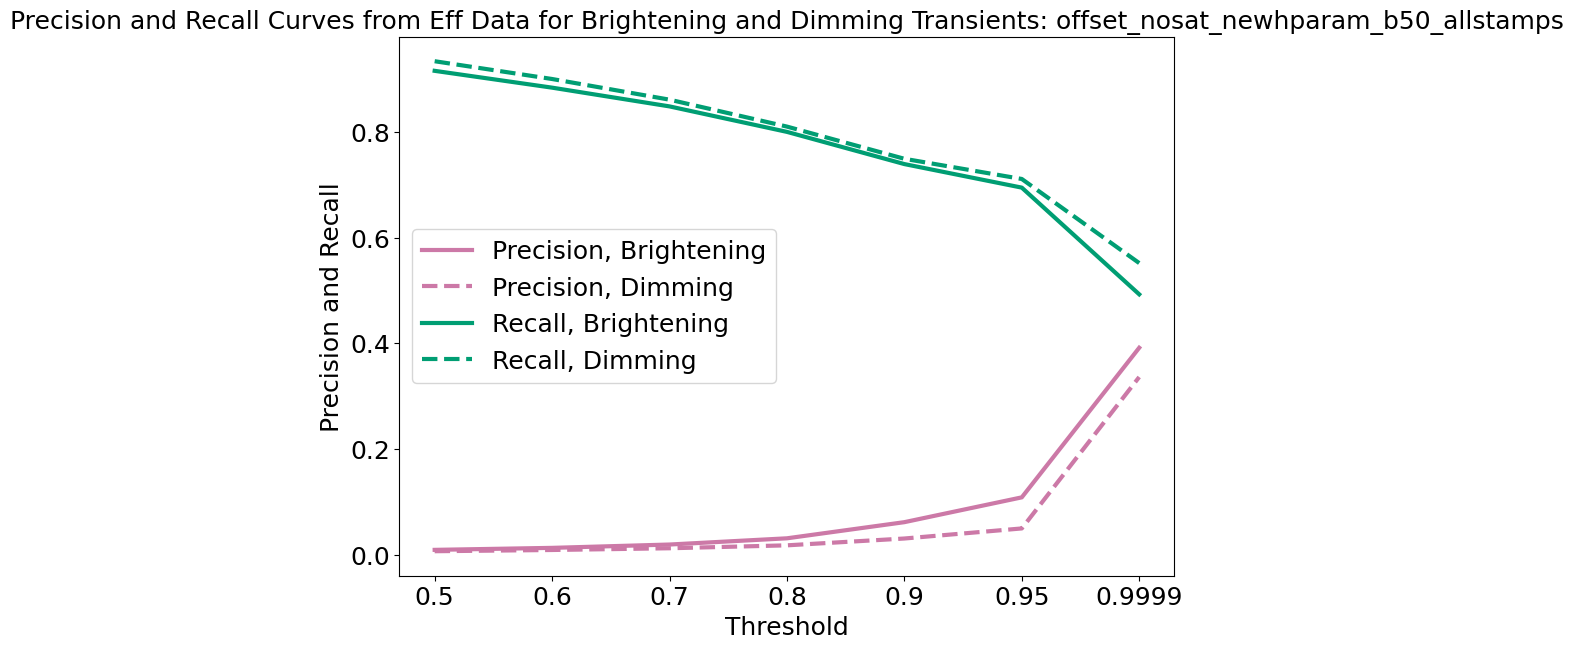

(array([0.00936753, 0.01314544, 0.01945777, 0.03121785, 0.06175465,
        0.1086771 , 0.3916185 ]),
 array([0.91545455, 0.88363636, 0.84818182, 0.8       , 0.73909091,
        0.69454545, 0.49272727]),
 array([0.00679345, 0.00912148, 0.01239318, 0.01792324, 0.03083255,
        0.04989791, 0.33628809]),
 array([0.93363636, 0.9       , 0.86090909, 0.81      , 0.74909091,
        0.71090909, 0.55181818]))

In [40]:
plot_precision_recall_from_eff_data("offset_nosat_newhparam_b50_allstamps")

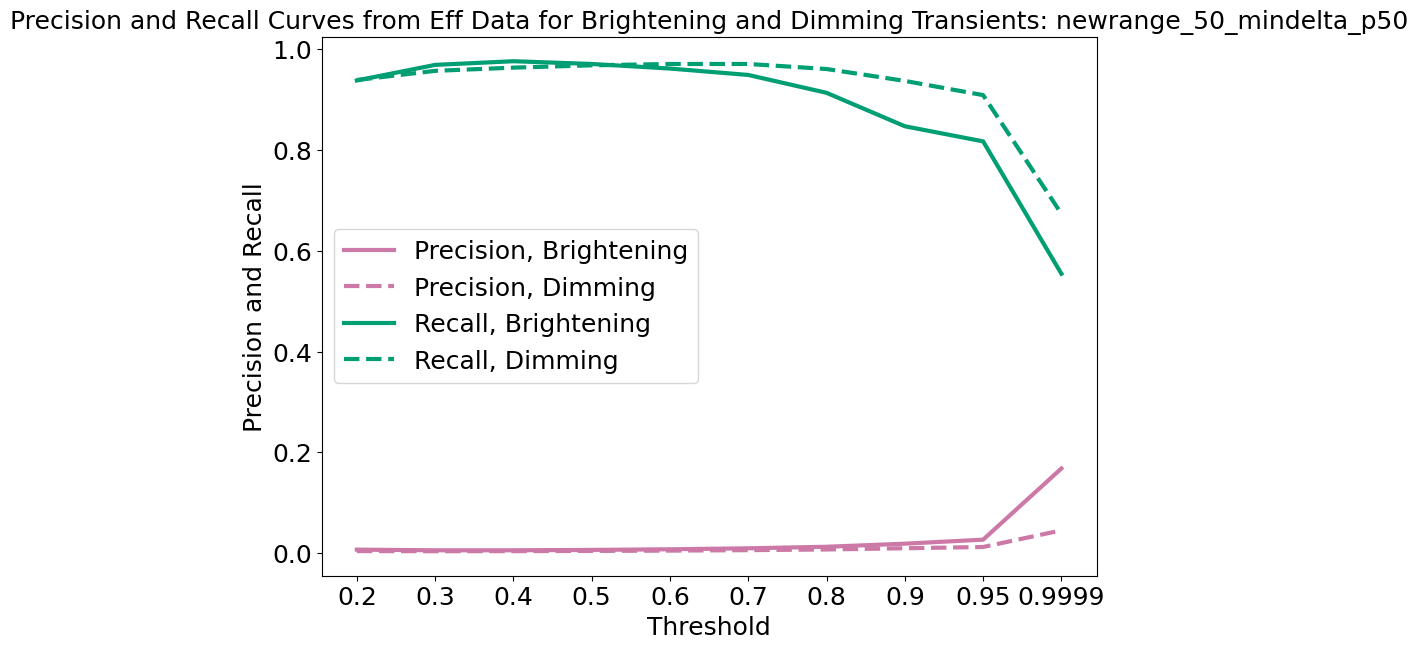

(array([0.00694449, 0.00566747, 0.00566746, 0.00639797, 0.00765507,
        0.00959876, 0.01265392, 0.0187612 , 0.0267472 , 0.1679978 ]),
 array([0.93818182, 0.96909091, 0.97636364, 0.97090909, 0.96181818,
        0.94909091, 0.91363636, 0.84727273, 0.81727273, 0.55454545]),
 array([0.00412433, 0.00379392, 0.00393923, 0.00437013, 0.00501448,
        0.00591559, 0.00727551, 0.00966605, 0.0122118 , 0.04519671]),
 array([0.93909091, 0.95727273, 0.96363636, 0.96818182, 0.97090909,
        0.97090909, 0.96090909, 0.93727273, 0.90909091, 0.67363636]))

In [38]:
plot_precision_recall_from_eff_data("newrange_50_mindelta_p50")

In [14]:
posneg='pos'
thr='0.2'
test_name='newrange_50_mindelta_p50'
df = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/new_eff_data/full_image_implantations_"+posneg+"/predsarrays_"+test_name+"/df_matched_thr_"+thr)

In [15]:
df

,Unnamed: 0.1,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,closest_y,...,brightness_ranking,quadrant,num_in_file_in_star,dup_indices,is_smaller_dup,dist_to_implant,row_from_implant,col_from_implant,A_from_implant,sig_from_implant
0,0,0,ztf_20221020148032_000686_zg_c07_x_0013.,3,pos,29.500000,195.000000,60,205.0,2088.0,...,20,3,278.0,[46],0.0,28.359302,44.0,233.0,5.00,3.0
1,1,1,ztf_20221020148032_000686_zg_c07_x_0013.,3,pos,16.651515,382.318182,66,394.0,2344.0,...,8,3,211.0,[],0.0,56.373578,83.0,394.0,1.15,6.0
2,2,2,ztf_20221020148032_000686_zg_c07_x_0013.,3,pos,18.942029,537.463768,69,548.0,936.0,...,9,3,242.0,[41],0.0,80.059767,109.0,548.0,1.40,4.0
3,3,3,ztf_20221020148032_000686_zg_c07_x_0013.,3,pos,24.851852,1955.651852,135,1973.0,938.0,...,0,3,187.0,[ 4 21],0.0,31.030729,65.0,1973.0,7.00,3.0
4,4,4,ztf_20221020148032_000686_zg_c07_x_0013.,3,pos,25.542857,1971.542857,105,1973.0,938.0,...,0,3,187.0,[ 3 21],1.0,30.670893,65.0,1973.0,7.00,3.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
148602,148602,148602,ztf_20221020148032_000686_zg_c03_x_0011.,3,neg,3054.450000,1799.550000,20,1811.0,1454.0,...,24,3,358.0,[],0.0,677.685476,2403.0,1957.0,2.00,3.0
148603,148603,148603,ztf_20221020148032_000686_zg_c03_x_0011.,3,neg,3049.500000,1955.000000,2,1959.0,1078.0,...,5,3,661.0,[148517],1.0,656.548742,2403.0,1957.0,2.00,3.0
148604,148604,148604,ztf_20221020148032_000686_zg_c03_x_0011.,3,neg,3051.666667,1771.333333,6,1811.0,1454.0,...,24,3,358.0,[148547 148556],0.0,681.689486,2403.0,1957.0,2.00,3.0
148605,148605,148605,ztf_20221020148032_000686_zg_c03_x_0011.,3,neg,3052.357143,2385.285714,14,2362.0,722.0,...,15,3,494.0,[148557 148562],1.0,632.710097,2448.0,2244.0,1.05,5.0


In [41]:
df.iloc[0]

Unnamed: 0.1                                                  0
Unnamed: 0                                                    0
filename               ztf_20221020148032_000686_zg_c07_x_0013.
quad                                                          3
type                                                        pos
row_from_nn                                                29.5
col_from_nn                                               195.0
detection_size                                               60
closest_x                                                 205.0
closest_y                                                2088.0
Diff                                                        0.0
brightness_ranking                                           20
quadrant                                                      3
num_in_file_in_star                                       278.0
dup_indices                                                [46]
is_smaller_dup                          

In [52]:
def plot_precision_recall_from_eff_data_limited_pos(test_name, minlim):
    threshes = ["0.5","0.6","0.7","0.8","0.9","0.95", "0.9999"]
    threshold=20
    precisions_pos = np.zeros(len(threshes))
    recalls_pos = np.zeros(len(threshes))
    precisions_neg = np.zeros(len(threshes))
    recalls_neg = np.zeros(len(threshes))
    for i, thr in enumerate(threshes):
        for posneg in ["pos","neg"]:
            df = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/new_eff_data/full_image_implantations_"+posneg+"/predsarrays_"+test_name+"/df_matched_thr_"+thr)
            if posneg=="pos":
                cut_len, implant_len = get_efficiency(df[df['A_from_implant']>minlim], df_implants_pos[df_implants_pos['A_from_implant']>minlim], threshold, posneg)
                # print(posneg, thr, len(df), cut_len, cut_len/len(df_implants_pos))
                precision = pr.precision(num_true_retrieved=cut_len, num_all_retrieved=len(df[df['A_from_implant']>minlim]))
                # print(precision)
                recall = pr.recall(num_true_retrieved=cut_len, num_all_true=implant_len)
                # print(recall)
                precisions_pos[i]=precision
                recalls_pos[i]=recall
            # else:
            #     cut_len, implant_len = get_efficiency(df[df['A_from_implant']>minlim], df_implants_neg[df_implants_neg['A_from_implant']>minlim], threshold, posneg)
            #     precision = pr.precision(num_true_retrieved=cut_len, num_all_retrieved=len(df[df['A_from_implant']>minlim]))
            #     recall = pr.recall(num_true_retrieved=cut_len, num_all_true=implant_len)
            #     precisions_neg[i]=precision
            #     recalls_neg[i]=recall
    plt.plot(threshes, precisions_pos, label="Precision, Brightening", linewidth=3, c="#cc79a7")
    # plt.plot(
    #     threshes,
    #     precisions_neg,
    #     label="Precision, Dimming",
    #     linewidth=3,
    #     linestyle="dashed",
    #     c="#cc79a7",
    # )
    plt.plot(threshes, recalls_pos, label="Recall, Brightening", linewidth=3, c="#009e73")
    # plt.plot(
    #     threshes,
    #     recalls_neg,
    #     label="Recall, Dimming",
    #     linewidth=3,
    #     linestyle="dashed",
    #     c="#009e73",
    # )

    plt.legend(fontsize=18)
    plt.title(
        "PR from Eff Data for Brightening and Dimming Transients: "+test_name+", min amp "+str(minlim), fontsize=18
    )
    plt.xlabel("Threshold", fontsize=18)
    plt.ylabel("Precision and Recall", fontsize=18)
    # plt.ylim(0.15, 1.01)
    plt.tick_params(axis="both", labelsize=18)
    plt.show()
    return precisions_pos, recalls_pos, precisions_neg, recalls_neg

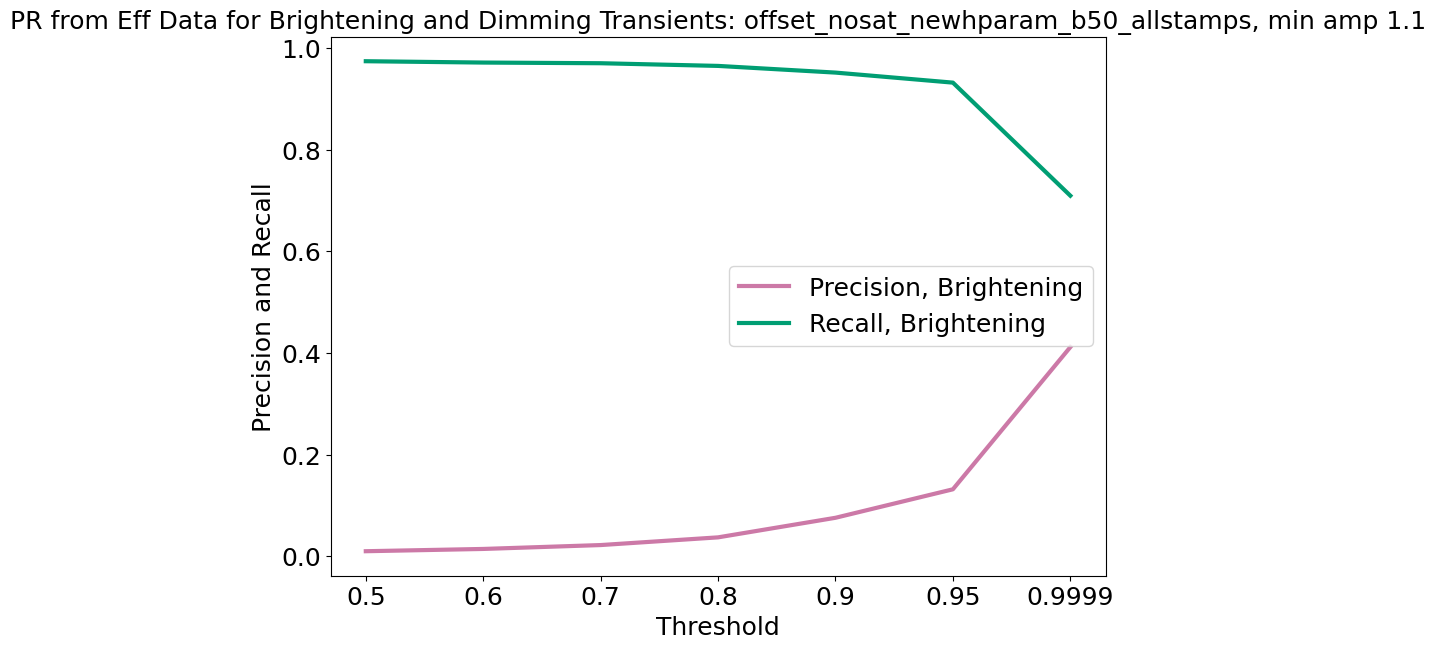

(array([0.00997197, 0.01444849, 0.02208902, 0.03723647, 0.07573853,
        0.13176996, 0.41145038]),
 array([0.97368421, 0.97105263, 0.96973684, 0.96447368, 0.95131579,
        0.93157895, 0.70921053]),
 array([0., 0., 0., 0., 0., 0., 0.]),
 array([0., 0., 0., 0., 0., 0., 0.]))

In [53]:
plot_precision_recall_from_eff_data_limited_pos("offset_nosat_newhparam_b50_allstamps", 1.1)

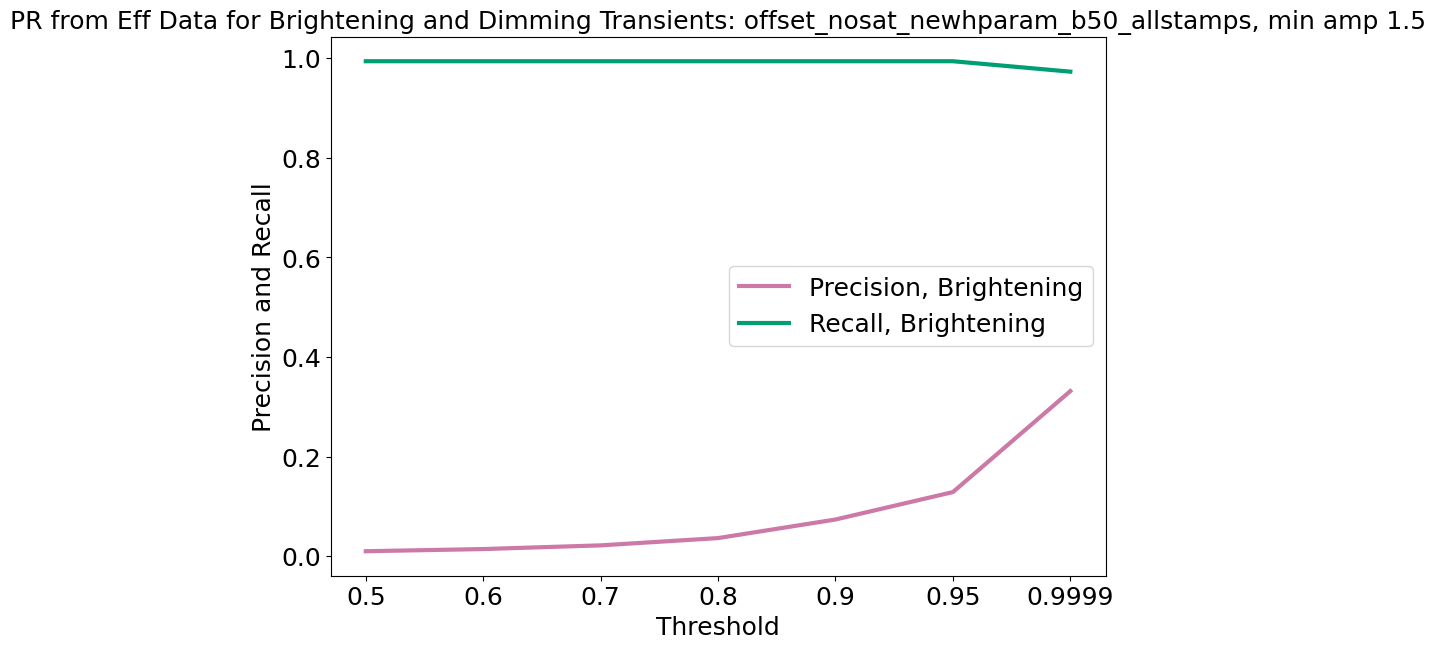

(array([0.0100826 , 0.01443227, 0.02184642, 0.03645547, 0.07376139,
        0.12883198, 0.33163265]),
 array([0.99401198, 0.99401198, 0.99401198, 0.99401198, 0.99401198,
        0.99401198, 0.97305389]),
 array([0., 0., 0., 0., 0., 0., 0.]),
 array([0., 0., 0., 0., 0., 0., 0.]))

In [54]:
plot_precision_recall_from_eff_data_limited_pos("offset_nosat_newhparam_b50_allstamps", 1.5)

In [56]:
np.unique(df_implants_pos['A_from_implant'], return_counts=True)

(array([ 1.005,  1.01 ,  1.05 ,  1.1  ,  1.15 ,  1.2  ,  1.3  ,  1.4  ,
         1.5  ,  2.   ,  5.   ,  7.   , 10.   ]),
 array([83, 86, 86, 85, 83, 82, 87, 88, 86, 88, 80, 80, 86]))

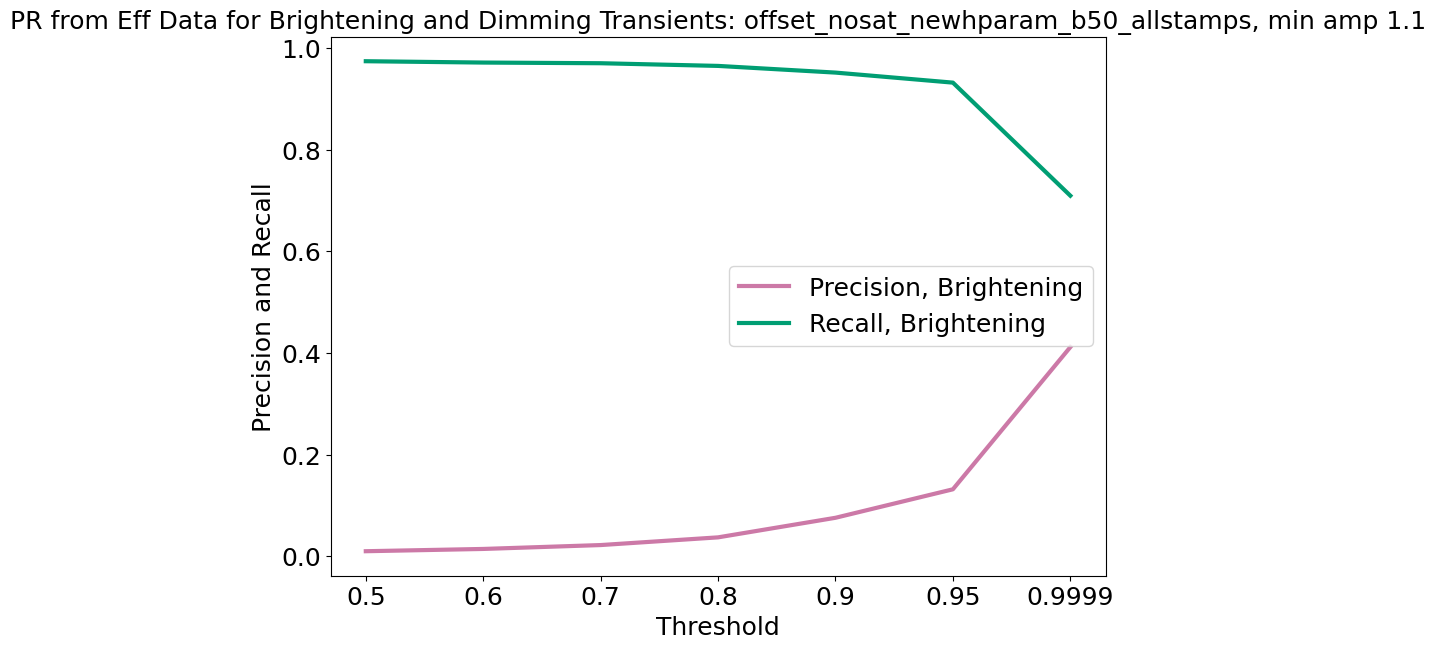

(array([0.00997197, 0.01444849, 0.02208902, 0.03723647, 0.07573853,
        0.13176996, 0.41145038]),
 array([0.97368421, 0.97105263, 0.96973684, 0.96447368, 0.95131579,
        0.93157895, 0.70921053]),
 array([0., 0., 0., 0., 0., 0., 0.]),
 array([0., 0., 0., 0., 0., 0., 0.]))

In [61]:
plot_precision_recall_from_eff_data_limited_pos("offset_nosat_newhparam_b50_allstamps", 1.1)

In [63]:
origin_info_te = np.load("/home/3155/saved_loss/offset_sat_newhparam_b50_allstamps_satdumbsplit_info_te.npy")

In [64]:
second_info_te = np.load("/home/3155/saved_loss/offset_sat_newhparam_b50_allstamps_satdumbsplit_folds_info_te.npy")

In [67]:
np.sum(origin_info_te-second_info_te)

0

In [65]:
second_info_te

array([[ 647,    0,    0, 2427,  331,    1],
       [ 382,    0,    4,  661,  799,    0],
       [ 476,    1,    9, 1574, 2757,    2],
       ...,
       [1099,    0,    0,  840, 1340,    0],
       [2460,    0,    0,  307,  230,  -12],
       [ 349,    0,    0, 1374, 1325,    2]])